## Cell 1 — Connect Google Drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Cell 2 — Paths, copy images to Colab

In [2]:
import os, shutil, glob, zipfile, re

DRIVE_DIR   = "/content/drive/MyDrive/Corneal_v2"            # <- your upload folder
CSV_NAME    = "Final_Features_MultiLabel_updated.csv"
IMG_NAME    = "Disease_Cell_Images"                           # zip OR folder with this name
LOCAL_DIR   = "/content/data_v2"
IMAGE_DIR   = os.path.join(LOCAL_DIR, "images")
RESULTS_DIR = "/content/drive/MyDrive/CNN_results_v2"         # NEW results folder
os.makedirs(LOCAL_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)

CSV_PATH = os.path.join(DRIVE_DIR, CSV_NAME)
assert os.path.exists(CSV_PATH), f"CSV not found: {CSV_PATH}"

if not os.path.isdir(IMAGE_DIR):
    zip_path, folder_path = os.path.join(DRIVE_DIR, IMG_NAME + ".zip"), os.path.join(DRIVE_DIR, IMG_NAME)
    if os.path.exists(zip_path):
        print("Unzipping", zip_path); zipfile.ZipFile(zip_path).extractall(IMAGE_DIR)
    elif os.path.isdir(folder_path):
        print("Copying folder", folder_path); shutil.copytree(folder_path, IMAGE_DIR)
    else:
        raise FileNotFoundError(f"Put {IMG_NAME}.zip or the {IMG_NAME}/ folder inside {DRIVE_DIR}")

IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
ALL_IMGS = [p for p in glob.glob(os.path.join(IMAGE_DIR, "**", "*"), recursive=True)
            if p.lower().endswith(IMG_EXT) and "__MACOSX" not in p]
print("Images found (all sub-folders):", len(ALL_IMGS))
print("Example file names:", [os.path.relpath(p, IMAGE_DIR) for p in ALL_IMGS[:8]])

Unzipping /content/drive/MyDrive/Corneal_v2/Disease_Cell_Images.zip
Images found (all sub-folders): 1543
Example file names: ['Disease_Cell_Images/NEB-2023-08-15288 R_SP.jpg', 'Disease_Cell_Images/NEB-2022-04-13822 R_SP.jpg', 'Disease_Cell_Images/NEB-2024-06-16136 R_SP.jpg', 'Disease_Cell_Images/NEB-2023-04-14947 R_SP.jpg', 'Disease_Cell_Images/NEB-2025-09-17464 L_SP.jpg', 'Disease_Cell_Images/NEB-2023-03-14825 R_SP.jpg', 'Disease_Cell_Images/NEB-2023-03-14907 R_SP.jpg', 'Disease_Cell_Images/NEB-2025-12-17726 L_SP.jpg']


## Cell 3 — Match every CSV row to its image  ⚠️ check this output
You want **Matched ≈ 1548 / 1548**. Unmatched rows are listed and saved to `unmatched_rows.csv`.

In [3]:
import pandas as pd
df = pd.read_csv(CSV_PATH)
print("CSV rows:", len(df))

def norm(s): return re.sub(r"[^a-z0-9]", "", str(s).lower())
def short_key(s):
    m = re.search(r"(\d{4,6})[\s_\-]*([LR])(?![A-Z])", str(s).upper())
    return f"{m.group(1)}{m.group(2)}" if m else None

full_map, short_map, dup = {}, {}, []
for p in ALL_IMGS:
    stem = os.path.splitext(os.path.basename(p))[0]
    k = norm(stem)
    if k in full_map: dup.append(stem)
    full_map.setdefault(k, p)
    sk = short_key(stem)
    if sk: short_map.setdefault(sk, []).append(p)

# pass 1: exact (normalised) name match
df["Img_Path"] = df["Tissue_ID"].map(lambda t: full_map.get(norm(t)))
# pass 2: tissue-number + eye fallback, only for images not already taken and only if unambiguous
taken = set(df["Img_Path"].dropna())
sk_rows = df[df["Img_Path"].isna()]["Tissue_ID"].map(short_key)
for i, k in sk_rows.items():
    cands = [p for p in short_map.get(k or "", []) if p not in taken]
    if len(cands) == 1 and (sk_rows == k).sum() == 1:
        df.at[i, "Img_Path"] = cands[0]; taken.add(cands[0])
unmatched = df[df["Img_Path"].isna()]
print(f"Matched: {df['Img_Path'].notna().sum()} / {len(df)}   | unmatched rows: {len(unmatched)}")
if dup: print("WARNING duplicate image names (first kept):", dup[:5])
if len(unmatched):
    print("Unmatched Tissue_IDs (first 15):", unmatched["Tissue_ID"].head(15).tolist())
used = set(df["Img_Path"].dropna())
print("Images not used by any CSV row:", len(set(ALL_IMGS) - used))
n_dup = df["Img_Path"].dropna().duplicated().sum()
print("Image used by >1 row:", n_dup)
assert n_dup == 0, "Two rows point to the same image - check file names"

# Stop if matching is clearly wrong
assert df["Img_Path"].notna().mean() > 0.9, "Less than 90% of rows matched an image - fix img matching before training!"
df = df[df["Img_Path"].notna()].reset_index(drop=True)
unmatched.to_csv(os.path.join(RESULTS_DIR, "unmatched_rows.csv"), index=False)

CSV rows: 1548
Matched: 1527 / 1548   | unmatched rows: 21
WARNING duplicate image names (first kept): ['NEB-2026-03-18084L_SP', 'NEB-2021-11 -13399 R_SP']
Unmatched Tissue_IDs (first 15): ['NEB-2020-09-12672 R', 'NEB-2020-09-12683 L', 'NEB-2020-10-12726 R', 'NEB-2020-10-12733 L', 'NEB-2022-10-14315 L', 'NEB-2022-10-14349 L', 'NEB-2023-02-14710 R', 'NEB-2023-04-14996 R', 'NEB-2023-08-15300 R', 'NEB-2024-06-16116 L', 'NEB-2024-06-16117 R', 'NEB-2024-06-16130 L', 'NEB-2024-08-16256 L', 'NEB-2024-08-16296 L', 'NEB-2025-09-17506 R']
Images not used by any CSV row: 16
Image used by >1 row: 0


## Cell 4 — Import libraries and check GPU

In [4]:
import json, time, copy, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score,
                             roc_curve, hamming_loss, accuracy_score)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NONE - turn on T4 GPU!")

device: cuda | GPU: Tesla T4


## Cell 5 — Settings, donor-grouped CV folds, check images
Uses `Split` from the CSV. Train rows are split into 5 folds grouped by `Donor_Group` (both eyes of a donor stay together).
Folds are saved once to `CNN_results_v2/cv_folds.csv` and re-used by every backbone, so results are comparable.

In [5]:
BACKBONE = "convnext_tiny"          # or "densenet121"
PRETRAINED = True
IMG_W, IMG_H = 384, 288
EPOCHS, WARMUP_EPOCHS, PATIENCE = 30, 2, 7
BATCH_SIZE = 16                     # if "CUDA out of memory" appears, change to 8
LR_HEAD, LR_BACKBONE, WEIGHT_DECAY = 1e-3, 1e-4, 1e-4
SEED = 42
N_FOLDS = 5
LABEL_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]

FUS_RUN   = os.path.join(RESULTS_DIR, f"fusion_{BACKBONE}")
FINAL_DIR = os.path.join(RESULTS_DIR, f"final_fusion_{BACKBONE}")
os.makedirs(FUS_RUN, exist_ok=True); os.makedirs(FINAL_DIR, exist_ok=True)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

fold_file = os.path.join(RESULTS_DIR, "cv_folds.csv")
if os.path.exists(fold_file):
    df = df.drop(columns=["CV_Fold"], errors="ignore").merge(pd.read_csv(fold_file), on="Tissue_ID", how="left")
    print("Loaded existing folds from", fold_file)
else:
    df["CV_Fold"] = -1
    tr_idx = df.index[df["Split"] == "train"]
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for k, (_, va) in enumerate(sgkf.split(tr_idx, df.loc[tr_idx, "Disease_Label"], df.loc[tr_idx, "Donor_Group"])):
        df.loc[tr_idx[va], "CV_Fold"] = k
    df[["Tissue_ID", "CV_Fold"]].to_csv(fold_file, index=False)
    print("Created new donor-grouped folds ->", fold_file)

train_df = df[df["Split"] == "train"].reset_index(drop=True)
test_df  = df[df["Split"] == "test"].reset_index(drop=True)
assert not set(train_df["Donor_Group"]) & set(test_df["Donor_Group"]), "Donor leakage between train and test!"
assert train_df["CV_Fold"].between(0, N_FOLDS - 1).all(), "Some train rows have no fold - delete cv_folds.csv and re-run"
print(f"{BACKBONE} | train {len(train_df)} | test {len(test_df)} | folds {N_FOLDS}")
print("Positives per fold:"); display(train_df.groupby("CV_Fold")[LABEL_COLS].sum().assign(n_images=train_df.groupby("CV_Fold").size()))

bad = [p for p in df["Img_Path"] if cv2.imread(p, cv2.IMREAD_GRAYSCALE) is None]
print("Unreadable images:", len(bad), bad[:5])
assert not bad, "Some images cannot be read by OpenCV - convert them to PNG/JPG"
pd.DataFrame({"Train": train_df[LABEL_COLS].sum(), "Test": test_df[LABEL_COLS].sum()})

Loaded existing folds from /content/drive/MyDrive/CNN_results_v2/cv_folds.csv
convnext_tiny | train 1222 | test 305 | folds 5
Positives per fold:


,FECD,Guttata,Folds,PolyPleo,LowCD,n_images
CV_Fold,,,,,,
0,15,36,111,48,53,230
1,26,29,124,65,70,251
2,21,25,121,62,64,246
3,27,40,125,60,60,247
4,25,26,137,57,66,248


Unreadable images: 0 []


,Train,Test
FECD,114,28
Guttata,156,38
Folds,618,154
PolyPleo,292,69
LowCD,313,75


## Cell 6 — Dataset, Fusion model and training functions (same as 06b)

In [6]:
IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
T = torchvision.transforms
TF_TRAIN = T.Compose([T.ToPILImage(),
                      T.RandomResizedCrop((IMG_H, IMG_W), scale=(0.7, 1.0), ratio=(1.25, 1.42)),
                      T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(15),
                      T.ColorJitter(brightness=0.2, contrast=0.2),
                      T.Grayscale(3), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])
TF_EVAL = T.Compose([T.ToPILImage(), T.Resize((IMG_H, IMG_W)),
                     T.Grayscale(3), T.ToTensor(), T.Normalize(IMNET_MEAN, IMNET_STD)])

def fit_tab_scaler(frame):
    imp = SimpleImputer(strategy="median").fit(frame[FEATURES])
    sc = StandardScaler().fit(imp.transform(frame[FEATURES]))
    return lambda f: sc.transform(imp.transform(f[FEATURES])).astype(np.float32)

class SPDataset(Dataset):
    def __init__(self, frame, tab, train):
        self.paths = list(frame["Img_Path"])
        self.Y = frame[LABEL_COLS].values.astype(np.float32)
        self.tab = torch.tensor(tab, dtype=torch.float32)
        self.tf = TF_TRAIN if train else TF_EVAL
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(cv2.imread(self.paths[i], cv2.IMREAD_GRAYSCALE)), self.tab[i], torch.tensor(self.Y[i])

def make_backbone(name, pretrained):
    W = "DEFAULT" if pretrained else None
    if name == "densenet121":
        m = models.densenet121(weights=W); dim = m.classifier.in_features; m.classifier = nn.Identity(); cam = m.features
    elif name in ("efficientnet_b0", "efficientnet_b2"):
        m = getattr(models, name)(weights=W); dim = m.classifier[1].in_features; m.classifier = nn.Identity(); cam = m.features[-1]
    elif name == "resnet50":
        m = models.resnet50(weights=W); dim = m.fc.in_features; m.fc = nn.Identity(); cam = m.layer4
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=W); dim = m.classifier[2].in_features; m.classifier[2] = nn.Identity(); cam = m.features[-1]
    else:
        raise ValueError(name)
    return m, dim, cam

class Fusion(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone, dim, self.cam_layer = make_backbone(BACKBONE, PRETRAINED)
        self.tab_mlp = nn.Sequential(nn.Linear(len(FEATURES), 32), nn.ReLU(), nn.Dropout(0.2),
                                     nn.Linear(32, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim + 32, 128), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(128, len(LABEL_COLS)))
    def forward(self, x, tab):
        return self.head(torch.cat([self.backbone(x), self.tab_mlp(tab)], 1))

def pos_weight(Y):
    pos = Y.sum(0); neg = len(Y) - pos
    return torch.tensor(np.clip(neg / np.maximum(pos, 1), 1, 10), dtype=torch.float32, device=DEVICE)

def make_loader(frame, scale, train):
    return DataLoader(SPDataset(frame, scale(frame), train), batch_size=BATCH_SIZE if train else 32,
                      shuffle=train, drop_last=train, num_workers=2, pin_memory=True)

@torch.no_grad()
def predict(model, dl):
    model.eval(); out = []
    for x, tab, _ in dl:
        x, tab = x.to(DEVICE), tab.to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            p = torch.sigmoid(model(x, tab)) + torch.sigmoid(model(torch.flip(x, dims=[3]), tab))
        out.append((p / 2).float().cpu().numpy())
    return np.concatenate(out)

def macro_auc(Y, P):
    return np.mean([roc_auc_score(Y[:, j], P[:, j]) for j in range(Y.shape[1]) if 0 < Y[:, j].sum() < len(Y)])

def train_one(ModelCls, tr_frame, va_frame=None, epochs=EPOCHS, log=True):
    set_seed()
    scale = fit_tab_scaler(tr_frame)
    tr_dl = make_loader(tr_frame, scale, True)
    va_dl = None if va_frame is None else make_loader(va_frame, scale, False)
    model = ModelCls().to(DEVICE)
    head_params = [p for n, p in model.named_parameters() if not n.startswith("backbone.")]
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight(tr_frame[LABEL_COLS].values))
    opt = torch.optim.AdamW([{"params": model.backbone.parameters(), "lr": LR_BACKBONE},
                             {"params": head_params, "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs - WARMUP_EPOCHS, 1))
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
    best, best_auc, best_ep, wait = None, -1, epochs, 0
    for ep in range(1, epochs + 1):
        warm = ep <= WARMUP_EPOCHS
        for p in model.backbone.parameters(): p.requires_grad = not warm
        model.train(); t0, losses = time.time(), []
        for x, tab, y in tr_dl:
            x, tab, y = x.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                loss = crit(model(x, tab), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); losses.append(loss.item())
        if not warm: sched.step()
        msg = f"  ep {ep:2d} loss {np.mean(losses):.4f}"
        if va_dl is not None:
            a = macro_auc(va_frame[LABEL_COLS].values, predict(model, va_dl)); msg += f" | val macro-AUC {a:.3f}"
            if a > best_auc: best_auc, best_ep, best, wait = a, ep, copy.deepcopy(model.state_dict()), 0
            elif not warm: wait += 1
        if log: print(msg + (" (warm-up)" if warm else "") + f" ({time.time() - t0:.0f}s)")
        if va_dl is not None and wait >= PATIENCE: break
    if best is not None: model.load_state_dict(best)
    for p in model.parameters(): p.requires_grad = True
    return model, scale, best_ep

print("OK - fusion model and training functions ready")

OK - fusion model and training functions ready


## Cell 7 — Fusion five-fold cross-validation (long — resumable)

In [7]:
oof_path, info_path = os.path.join(FUS_RUN, "oof_predictions.csv"), os.path.join(FUS_RUN, "fold_info.json")
oof = pd.read_csv(oof_path) if os.path.exists(oof_path) else \
      train_df[["Tissue_ID", "CV_Fold"] + LABEL_COLS].assign(**{f"P_{l}": np.nan for l in LABEL_COLS})
fus_folds = json.load(open(info_path)) if os.path.exists(info_path) else {}

for k in range(N_FOLDS):
    if str(k) in fus_folds:
        print(f"Fold {k} already done (val macro-AUC {fus_folds[str(k)]['val_macro_auc']:.3f}) - skipping"); continue
    tr_f, va_f = train_df[train_df["CV_Fold"] != k], train_df[train_df["CV_Fold"] == k]
    print(f"\n===== Fusion {BACKBONE} | fold {k} | train {len(tr_f)} / val {len(va_f)} =====")
    t0 = time.time()
    model, scale, best_ep = train_one(Fusion, tr_f, va_f)
    P = predict(model, make_loader(va_f, scale, False))
    oof.loc[oof["Tissue_ID"].isin(va_f["Tissue_ID"]), [f"P_{l}" for l in LABEL_COLS]] = P
    oof.to_csv(oof_path, index=False)
    fus_folds[str(k)] = {"best_epoch": int(best_ep), "val_macro_auc": float(macro_auc(va_f[LABEL_COLS].values, P)),
                         "minutes": round((time.time() - t0) / 60, 1)}
    json.dump(fus_folds, open(info_path, "w"), indent=2)
    print(f"Fold {k}: val macro-AUC {fus_folds[str(k)]['val_macro_auc']:.3f}, best epoch {best_ep} - SAVED to Drive")
    del model; torch.cuda.empty_cache()

# CV summary + per-disease thresholds (Youden on out-of-fold predictions)
o = pd.read_csv(oof_path).drop_duplicates("Tissue_ID").set_index("Tissue_ID").loc[list(train_df["Tissue_ID"])]
Y_CV, P_CV = o[LABEL_COLS].values, o[[f"P_{l}" for l in LABEL_COLS]].values

def youden(y, p):
    fpr, tpr, thr = roc_curve(y, p); return float(np.clip(thr[np.argmax(tpr - fpr)], 0.01, 0.99))
THRESH = {lab: youden(Y_CV[:, j], P_CV[:, j]) for j, lab in enumerate(LABEL_COLS)}

cv_auc = pd.Series({lab: roc_auc_score(Y_CV[:, j], P_CV[:, j]) for j, lab in enumerate(LABEL_COLS)})
cv_auc["Macro AUC"] = cv_auc.mean()
cv_auc.to_frame("Fusion CV ROC-AUC").to_csv(os.path.join(FINAL_DIR, "cv_auc_fusion.csv"))
print(f"\nFUSION {BACKBONE} - 5-fold CV ROC-AUC per disease"); display(cv_auc.round(3).to_frame("CV ROC-AUC").T)
print("Thresholds:", {k: round(v, 3) for k, v in THRESH.items()})


===== Fusion convnext_tiny | fold 0 | train 992 / val 230 =====
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 195MB/s] 


  ep  1 loss 0.9990 | val macro-AUC 0.756 (warm-up) (27s)
  ep  2 loss 0.8031 | val macro-AUC 0.829 (warm-up) (21s)
  ep  3 loss 0.7596 | val macro-AUC 0.853 (26s)
  ep  4 loss 0.6954 | val macro-AUC 0.852 (23s)
  ep  5 loss 0.6514 | val macro-AUC 0.863 (30s)
  ep  6 loss 0.6321 | val macro-AUC 0.859 (29s)
  ep  7 loss 0.6265 | val macro-AUC 0.878 (23s)
  ep  8 loss 0.5878 | val macro-AUC 0.875 (23s)
  ep  9 loss 0.5726 | val macro-AUC 0.869 (23s)
  ep 10 loss 0.5589 | val macro-AUC 0.882 (24s)
  ep 11 loss 0.5306 | val macro-AUC 0.875 (23s)
  ep 12 loss 0.4900 | val macro-AUC 0.873 (23s)
  ep 13 loss 0.4771 | val macro-AUC 0.873 (24s)
  ep 14 loss 0.4426 | val macro-AUC 0.880 (24s)
  ep 15 loss 0.4191 | val macro-AUC 0.873 (24s)
  ep 16 loss 0.3810 | val macro-AUC 0.870 (23s)
  ep 17 loss 0.3510 | val macro-AUC 0.867 (23s)
Fold 0: val macro-AUC 0.882, best epoch 10 - SAVED to Drive

===== Fusion convnext_tiny | fold 1 | train 971 / val 251 =====
  ep  1 loss 1.0005 | val macro-AUC 0.7

,FECD,Guttata,Folds,PolyPleo,LowCD,Macro AUC
CV ROC-AUC,0.885,0.829,0.778,0.868,0.987,0.869


Thresholds: {'FECD': 0.351, 'Guttata': 0.445, 'Folds': 0.464, 'PolyPleo': 0.494, 'LowCD': 0.694}


## Cell 8 — Train the final fusion model on all training images

In [8]:
ep = max(int(np.median([v["best_epoch"] for v in fus_folds.values()])), WARMUP_EPOCHS + 1)
print(f"--- Final fusion {BACKBONE}: {ep} epochs on all {len(train_df)} train images")
final_model, final_scale, _ = train_one(Fusion, train_df, None, epochs=ep)
P_TE = predict(final_model, make_loader(test_df, final_scale, False))
Y_TE = test_df[LABEL_COLS].values
torch.save(final_model.state_dict(), os.path.join(FINAL_DIR, f"Fusion_{BACKBONE}.pt"))
print("Saved model ->", os.path.join(FINAL_DIR, f"Fusion_{BACKBONE}.pt"))

--- Final fusion convnext_tiny: 12 epochs on all 1222 train images
  ep  1 loss 0.9821 (warm-up) (20s)
  ep  2 loss 0.7512 (warm-up) (20s)
  ep  3 loss 0.7423 (24s)
  ep  4 loss 0.6806 (23s)
  ep  5 loss 0.6394 (23s)
  ep  6 loss 0.6060 (24s)
  ep  7 loss 0.5850 (24s)
  ep  8 loss 0.5723 (23s)
  ep  9 loss 0.5365 (23s)
  ep 10 loss 0.5248 (24s)
  ep 11 loss 0.4879 (24s)
  ep 12 loss 0.4872 (23s)
Saved model -> /content/drive/MyDrive/CNN_results_v2/final_fusion_convnext_tiny/Fusion_convnext_tiny.pt


## Cell 9 — Held-out test evaluation

In [9]:
pred = (P_TE >= np.array([THRESH[l] for l in LABEL_COLS])).astype(int)
per = pd.DataFrame({lab: {"ROC_AUC": roc_auc_score(Y_TE[:, j], P_TE[:, j]),
                          "PR_AUC": average_precision_score(Y_TE[:, j], P_TE[:, j]),
                          "F1": f1_score(Y_TE[:, j], pred[:, j], zero_division=0),
                          "Sensitivity": recall_score(Y_TE[:, j], pred[:, j], zero_division=0),
                          "Specificity": recall_score(Y_TE[:, j], pred[:, j], pos_label=0, zero_division=0)}
                    for j, lab in enumerate(LABEL_COLS)}).T
normal = (Y_TE.sum(1) == 0).astype(int)
overall = {"Macro ROC-AUC": per["ROC_AUC"].mean(), "Macro F1": f1_score(Y_TE, pred, average="macro", zero_division=0),
           "Hamming loss": hamming_loss(Y_TE, pred), "Exact match": accuracy_score(Y_TE, pred),
           "Normal-vs-disease AUC": roc_auc_score(1 - normal, P_TE.max(1))}

rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(Y_TE), len(Y_TE)) for _ in range(1000)]
per["ROC_AUC 95% CI"] = [
    "{:.2f}-{:.2f}".format(*np.percentile([roc_auc_score(Y_TE[i, j], P_TE[i, j]) for i in boot_idx
                                           if 0 < Y_TE[i, j].sum() < len(i)], [2.5, 97.5]))
    for j in range(len(LABEL_COLS))]
per.to_csv(os.path.join(FINAL_DIR, "test_metrics_fusion.csv"))

print(f"HELD-OUT TEST - Fusion {BACKBONE} (n={len(test_df)})"); display(per.round(3))
print("Overall (test)"); display(pd.Series(overall).round(3).to_frame("Fusion"))

HELD-OUT TEST - Fusion convnext_tiny (n=305)


,ROC_AUC,PR_AUC,F1,Sensitivity,Specificity,ROC_AUC 95% CI
FECD,0.932,0.565,0.479,1.000,0.780,0.90-0.96
Guttata,0.870,0.632,0.538,0.658,0.888,0.80-0.93
Folds,0.803,0.738,0.754,0.825,0.629,0.75-0.85
PolyPleo,0.866,0.594,0.683,0.797,0.843,0.82-0.91
LowCD,0.982,0.875,0.942,0.973,0.970,0.96-1.00


Overall (test)


,Fusion
Macro ROC-AUC,0.890
Macro F1,0.679
Hamming loss,0.162
Exact match,0.446
Normal-vs-disease AUC,0.879


## Cell 10 — Plot test ROC curves

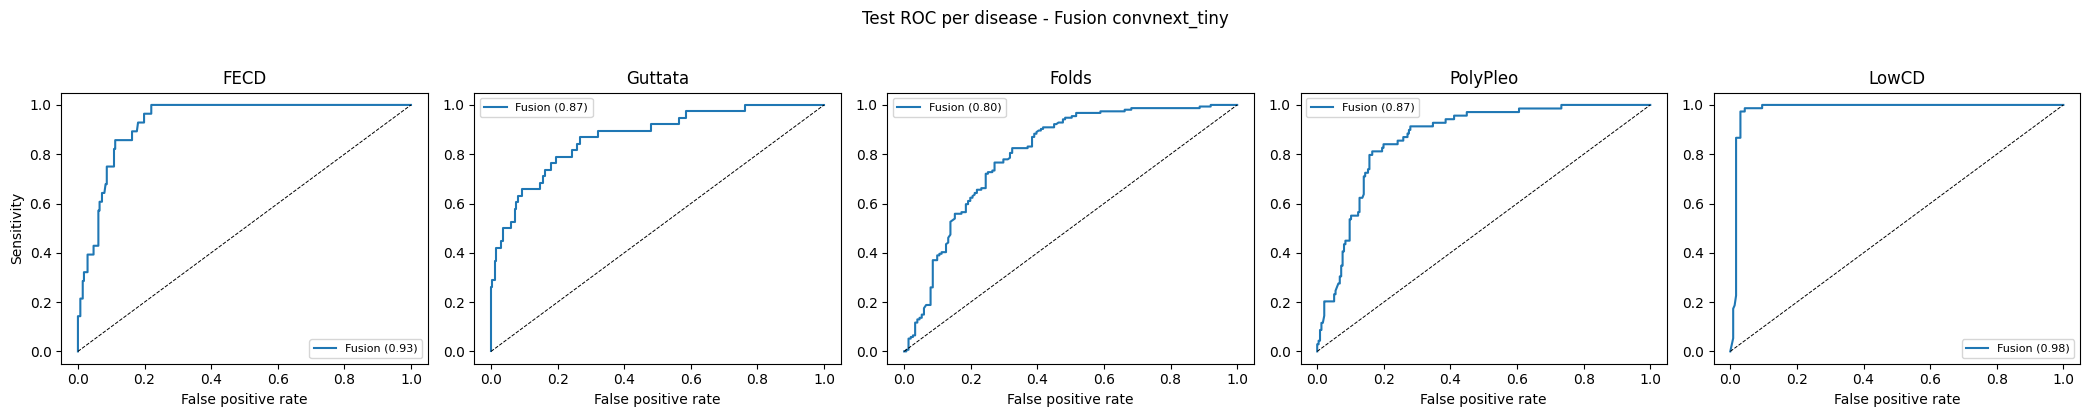

In [10]:
fig, axes = plt.subplots(1, len(LABEL_COLS), figsize=(4.2 * len(LABEL_COLS), 4))
for j, lab in enumerate(LABEL_COLS):
    fpr, tpr, _ = roc_curve(Y_TE[:, j], P_TE[:, j])
    axes[j].plot(fpr, tpr, label=f"Fusion ({per.loc[lab, 'ROC_AUC']:.2f})")
    axes[j].plot([0, 1], [0, 1], "k--", lw=0.7)
    axes[j].set(title=lab, xlabel="False positive rate"); axes[j].legend(fontsize=8)
axes[0].set_ylabel("Sensitivity")
plt.suptitle(f"Test ROC per disease - Fusion {BACKBONE}", y=1.03); plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "test_roc_fusion.png"), dpi=120, bbox_inches="tight"); plt.show()

## Cell 11 — Grad-CAM visualisations (fusion model)

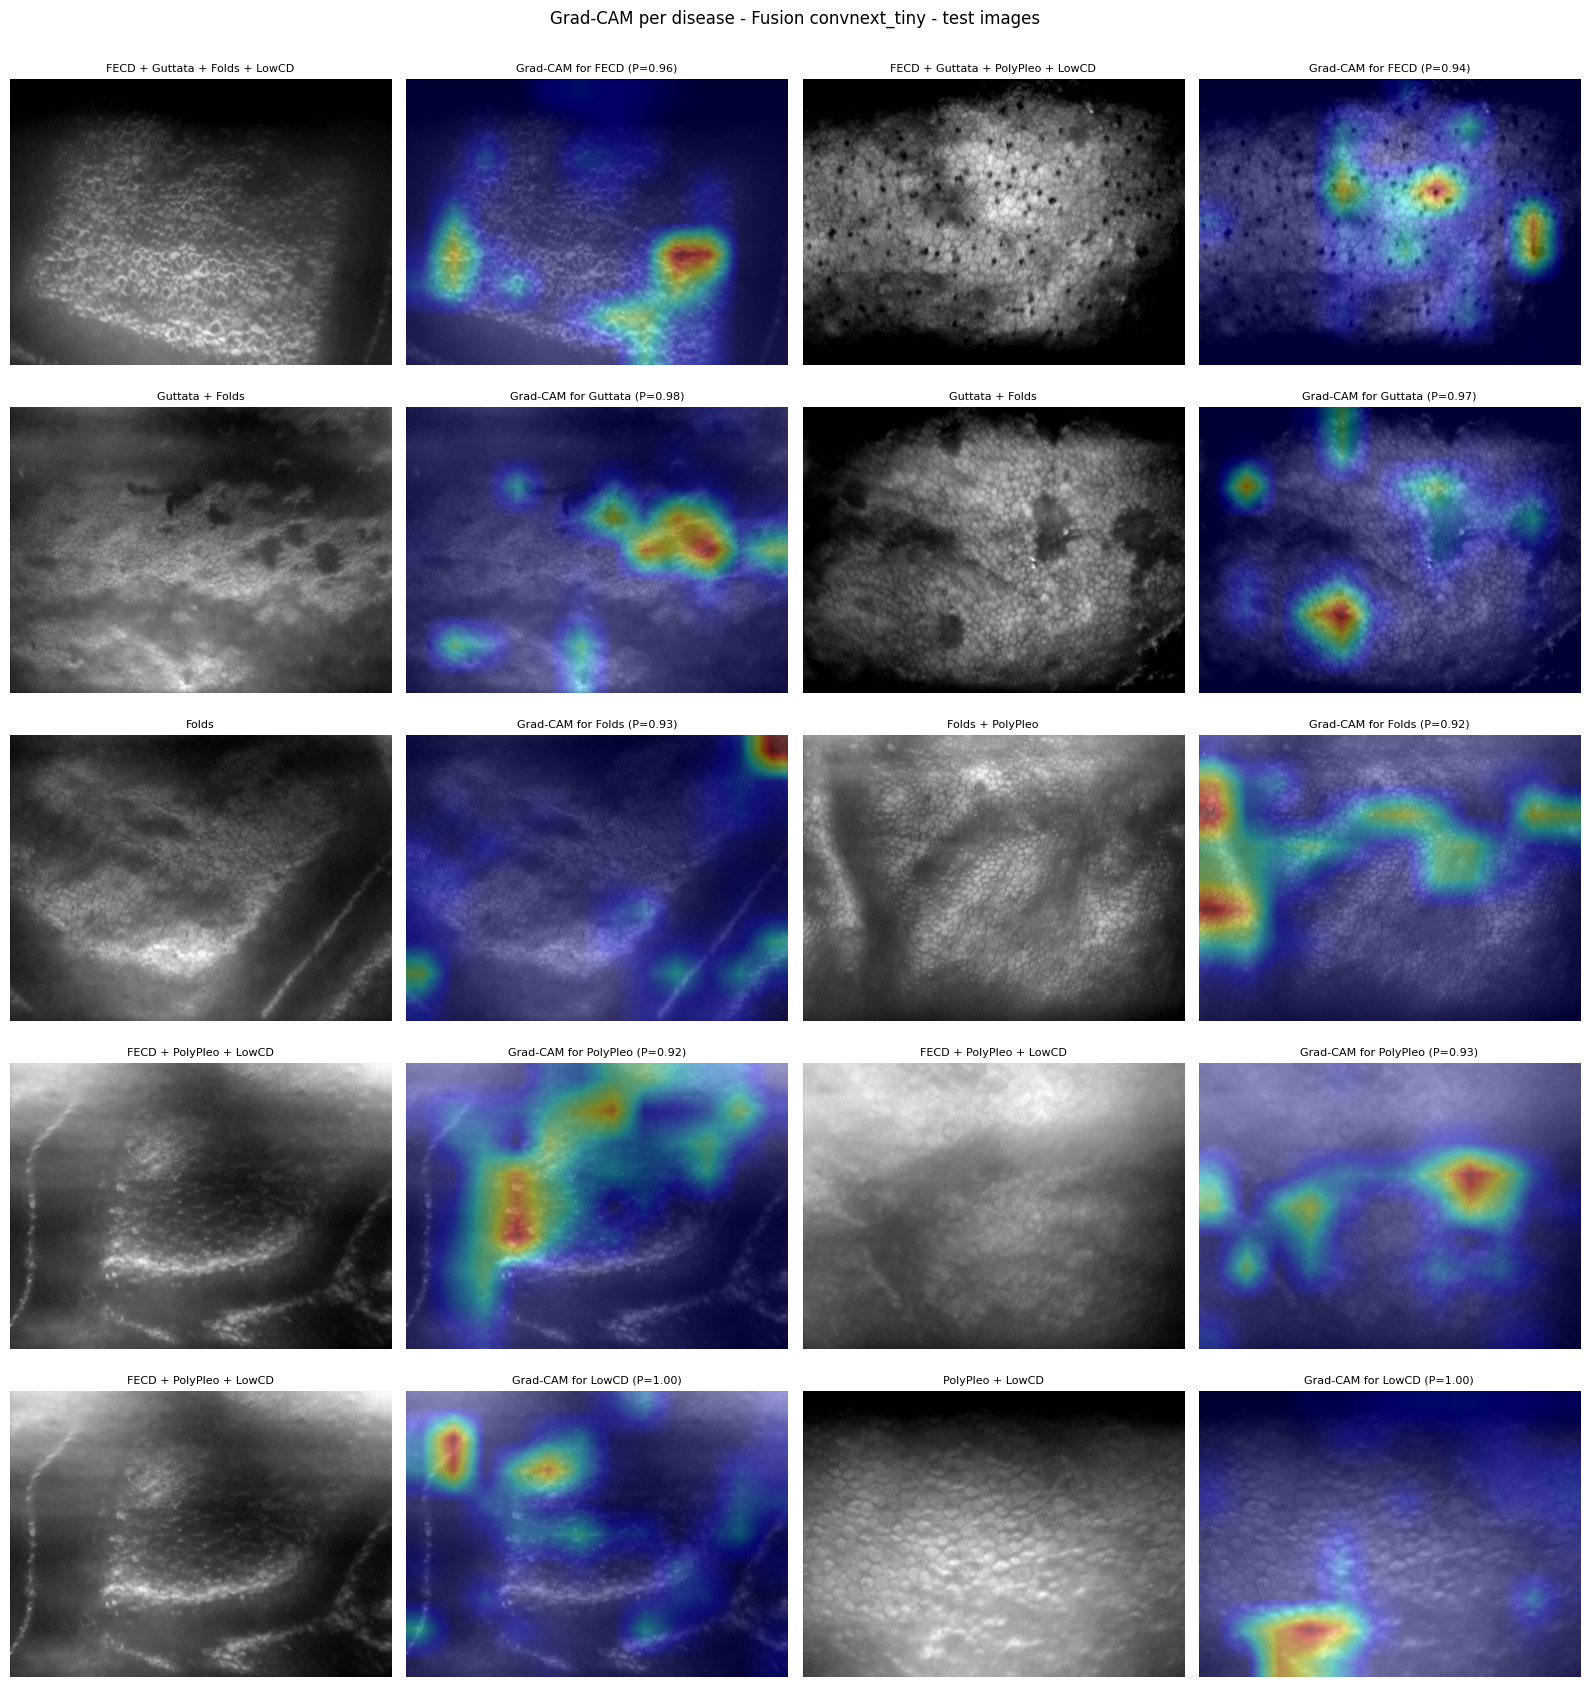

In [11]:
class GradCAM:
    def __init__(self, model):
        self.model, self.acts, self.grads = model.eval(), None, None
        def hook(m, i, o):
            self.acts = o; o.register_hook(lambda g: setattr(self, "grads", g))
        self.h = model.cam_layer.register_forward_hook(hook)
    def __call__(self, x, tab, label_idx):
        self.model.zero_grad()
        logit = self.model(x, tab)[0, label_idx]; logit.backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((w * self.acts).sum(1)).squeeze().detach().float().cpu().numpy()
        cam = cv2.resize(cam, (IMG_W, IMG_H))
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), torch.sigmoid(logit).item()
    def remove(self): self.h.remove()

ds = SPDataset(test_df, final_scale(test_df), False)
gc = GradCAM(final_model)
fig, axes = plt.subplots(len(LABEL_COLS), 4, figsize=(16, 3.4 * len(LABEL_COLS)))
for j, lab in enumerate(LABEL_COLS):
    pos = np.where(Y_TE[:, j] == 1)[0]
    for c, i in enumerate(pos[np.argsort(-P_TE[pos, j])][:2]):          # 2 most confident true cases per disease
        x, tab, _ = ds[i]
        cam, p = gc(x.unsqueeze(0).to(DEVICE), tab.unsqueeze(0).to(DEVICE), j)
        raw = cv2.resize(cv2.imread(ds.paths[i], 0), (IMG_W, IMG_H))
        axes[j, 2 * c].imshow(raw, cmap="gray"); axes[j, 2 * c].set_title(test_df.loc[i, "Combination"], fontsize=8)
        axes[j, 2 * c + 1].imshow(raw, cmap="gray"); axes[j, 2 * c + 1].imshow(cam, cmap="jet", alpha=0.4)
        axes[j, 2 * c + 1].set_title(f"Grad-CAM for {lab} (P={p:.2f})", fontsize=8)
    for a in axes[j]: a.axis("off")
gc.remove()
plt.suptitle(f"Grad-CAM per disease - Fusion {BACKBONE} - test images", y=1.0); plt.tight_layout()
plt.savefig(os.path.join(FINAL_DIR, "gradcam_fusion.png"), dpi=110, bbox_inches="tight"); plt.show()

## Cell 12 — Save predictions and summary

In [12]:
out = test_df[["Tissue_ID", "Donor_Group", "Combination"] + LABEL_COLS].copy()
for j, lab in enumerate(LABEL_COLS):
    out[f"P_Fus_{lab}"] = P_TE[:, j]; out[f"Pred_Fus_{lab}"] = pred[:, j]
out.to_csv(os.path.join(FINAL_DIR, "test_predictions_fusion.csv"), index=False)

json.dump({"backbone": BACKBONE, "model": "fusion (image + 6 biomarkers)", "dataset": CSV_NAME,
           "n_train": len(train_df), "n_test": len(test_df), "thresholds": THRESH,
           "cv_auc": cv_auc.round(4).to_dict(),
           "test_metrics": per.drop(columns="ROC_AUC 95% CI").round(4).to_dict(orient="index"),
           "test_auc_ci": per["ROC_AUC 95% CI"].to_dict(),
           "test_overall": {m: round(float(v), 4) for m, v in overall.items()},
           "fusion_epochs": [v["best_epoch"] for v in fus_folds.values()], "final_epochs": ep},
          open(os.path.join(FINAL_DIR, "summary_fusion.json"), "w"), indent=2)
print("Saved everything to", FINAL_DIR)
print(os.listdir(FINAL_DIR))

Saved everything to /content/drive/MyDrive/CNN_results_v2/final_fusion_convnext_tiny
['cv_auc_fusion.csv', 'Fusion_convnext_tiny.pt', 'test_metrics_fusion.csv', 'test_roc_fusion.png', 'gradcam_fusion.png', 'test_predictions_fusion.csv', 'summary_fusion.json']
